<a href="https://colab.research.google.com/github/merveedmrcglu/eem4011-proje/blob/main/NSTDB_R_Tepesi_Tespiti_Analiz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kayıt: 118e24 | Örnekleme: 360 Hz | Görüntülenen süre: 10.0 saniye
İlk 10 saniyedeki referans tepe sayısı: 13


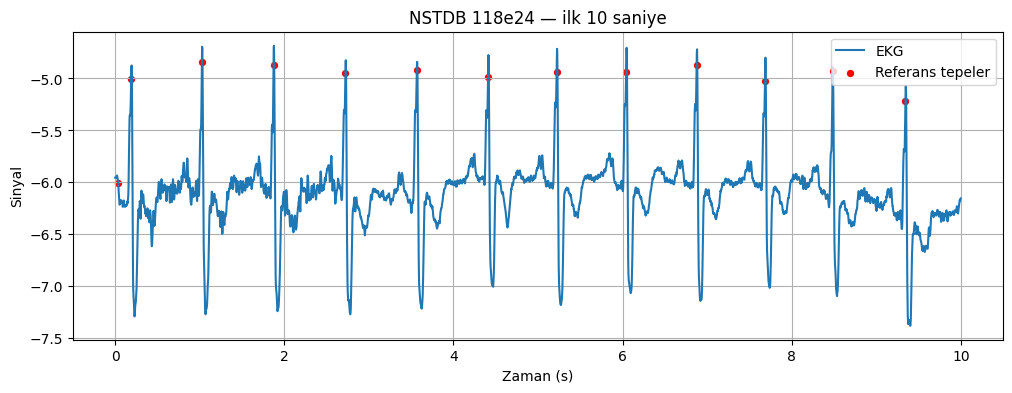

In [ ]:
!pip -q install wfdb

import wfdb
import numpy as np
import matplotlib.pyplot as plt

record_name = "118e24"
record = wfdb.rdrecord(record_name, pn_dir="nstdb")
ann = wfdb.rdann(record_name, "atr", pn_dir="nstdb")

fs = record.fs
signal = record.p_signal[:, 0]
n = min(len(signal), 10 * fs)
times = np.arange(n) / fs
peak_samples = ann.sample[ann.sample < n]

print(f"Kayıt: {record_name} | Örnekleme: {fs} Hz | Görüntülenen süre: {n/fs:.1f} saniye")
print(f"İlk 10 saniyedeki referans tepe sayısı: {len(peak_samples)}")

plt.figure(figsize=(12, 4))
plt.plot(times, signal[:n], label="EKG")
plt.scatter(peak_samples / fs, signal[peak_samples], color="red", s=18, label="Referans tepeler")
plt.xlabel("Zaman (s)")
plt.ylabel("Sinyal")
plt.title("NSTDB 118e24 — ilk 10 saniye")
plt.legend()
plt.grid()
plt.show()

In [ ]:
from scipy.signal import find_peaks

# Aynı yöntemi daha sonra filtrelenmiş sinyallerde de kullanacağız.
predicted, _ = find_peaks(
    signal[:n],
    distance=int(0.30 * fs),
    prominence=0.5
)

reference = ann.sample[ann.sample < n]
tolerance = int(0.15 * fs)

matched = set()
tp = 0

for r in reference:
    candidates = [
        int(p) for p in predicted
        if int(p) not in matched and abs(int(p) - int(r)) <= tolerance
    ]
    if candidates:
        closest = min(candidates, key=lambda p: abs(p - int(r)))
        matched.add(closest)
        tp += 1

fp = len(predicted) - tp
fn = len(reference) - tp
f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0

print(f"Bulunan tepe: {len(predicted)} | TP: {tp} | FP: {fp} | FN: {fn}")
print(f"İlk 10 saniyelik deneme F1: {f1:.3f}")

Bulunan tepe: 12 | TP: 12 | FP: 0 | FN: 1
İlk 10 saniyelik deneme F1: 0.960


Kaçan referans tepe zamanı (s): [0.036]


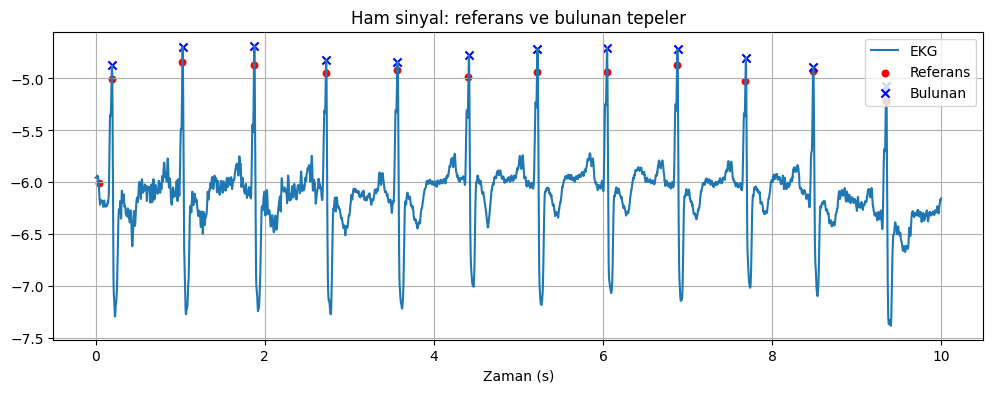

In [ ]:
missed = [
    int(r) for r in reference
    if all(abs(int(r) - p) > tolerance for p in matched)
]

print("Kaçan referans tepe zamanı (s):", [round(r / fs, 3) for r in missed])

plt.figure(figsize=(12, 4))
plt.plot(times, signal[:n], label="EKG")
plt.scatter(reference / fs, signal[reference], color="red", s=22, label="Referans")
plt.scatter(predicted / fs, signal[predicted], color="blue", marker="x", s=35, label="Bulunan")
plt.xlabel("Zaman (s)")
plt.title("Ham sinyal: referans ve bulunan tepeler")
plt.legend()
plt.grid()
plt.show()

In [ ]:
for sample, symbol in zip(ann.sample, ann.symbol):
    if sample < n:
        print(f"{sample / fs:.3f} s  |  {symbol}")

0.036 s  |  +
0.189 s  |  R
1.025 s  |  R
1.872 s  |  R
2.722 s  |  R
3.567 s  |  R
4.408 s  |  R
5.219 s  |  R
6.042 s  |  R
6.875 s  |  R
7.683 s  |  R
8.483 s  |  R
9.344 s  |  R


In [ ]:
beat_symbols = set("NLRBAaJSVrFejnE/fQ?")

reference_beats = np.array([
    int(sample)
    for sample, symbol in zip(ann.sample, ann.symbol)
    if int(sample) < n and symbol in beat_symbols
])

matched = set()
tp = 0

for r in reference_beats:
    candidates = [
        int(p) for p in predicted
        if int(p) not in matched and abs(int(p) - int(r)) <= tolerance
    ]
    if candidates:
        closest = min(candidates, key=lambda p: abs(p - int(r)))
        matched.add(closest)
        tp += 1

fp = len(predicted) - tp
fn = len(reference_beats) - tp
f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0

print(f"Atım anotasyonu: {len(reference_beats)} | TP: {tp} | FP: {fp} | FN: {fn}")
print(f"İlk 10 saniye için ön F1: {f1:.3f}")


Atım anotasyonu: 12 | TP: 12 | FP: 0 | FN: 0
İlk 10 saniye için ön F1: 1.000


In [ ]:
n_full = len(signal)
predicted_full, _ = find_peaks(
    signal,
    distance=int(0.30 * fs),
    prominence=0.5
)

reference_full = np.array([
    int(sample)
    for sample, symbol in zip(ann.sample, ann.symbol)
    if symbol in beat_symbols
])

tolerance = int(0.15 * fs)
matched_full = set()
tp = 0

for r in reference_full:
    candidates = [
        int(p) for p in predicted_full
        if int(p) not in matched_full and abs(int(p) - int(r)) <= tolerance
    ]
    if candidates:
        closest = min(candidates, key=lambda p: abs(p - int(r)))
        matched_full.add(closest)
        tp += 1

fp = len(predicted_full) - tp
fn = len(reference_full) - tp
f1_full = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0

print(f"Kayıt: 118e24 | Süre: {n_full / fs / 60:.1f} dakika")
print(f"Referans atım: {len(reference_full)} | Bulunan: {len(predicted_full)}")
print(f"TP: {tp} | FP: {fp} | FN: {fn} | F1: {f1_full:.3f}")

Kayıt: 118e24 | Süre: 30.1 dakika
Referans atım: 2278 | Bulunan: 2414
TP: 2278 | FP: 136 | FN: 0 | F1: 0.971


Fazladan tepe sayısı: 136
İlk 10 fazladan tepe zamanı (s): [308.622 325.9   327.669 331.769 337.636 341.664 348.075 349.772 361.65
 363.164]


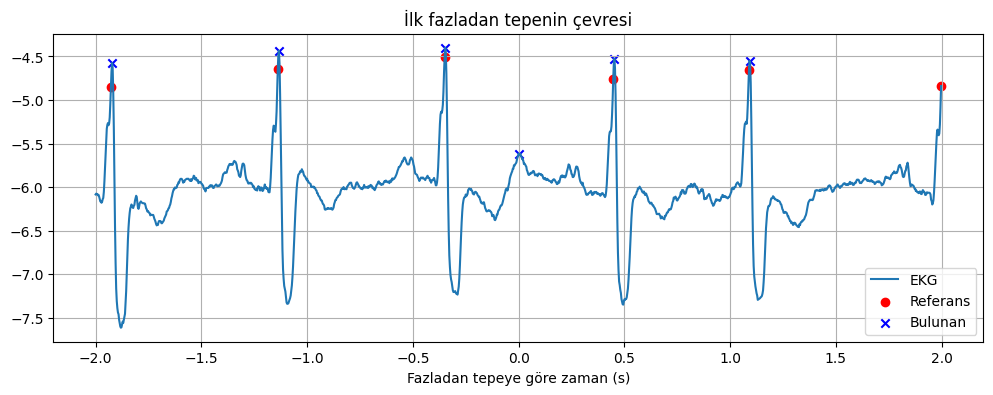

In [ ]:
false_positives = np.array([
    int(p) for p in predicted_full
    if int(p) not in matched_full
])

print("Fazladan tepe sayısı:", len(false_positives))
print("İlk 10 fazladan tepe zamanı (s):",
      np.round(false_positives[:10] / fs, 3))

p = false_positives[0]
left = max(0, p - 2 * fs)
right = min(len(signal), p + 2 * fs)

near_reference = reference_full[
    (reference_full >= left) & (reference_full < right)
]
near_predictions = predicted_full[
    (predicted_full >= left) & (predicted_full < right)
]

plt.figure(figsize=(12, 4))
plt.plot((np.arange(left, right) - p) / fs, signal[left:right], label="EKG")
plt.scatter((near_reference - p) / fs, signal[near_reference],
            color="red", label="Referans")
plt.scatter((near_predictions - p) / fs, signal[near_predictions],
            color="blue", marker="x", label="Bulunan")
plt.xlabel("Fazladan tepeye göre zaman (s)")
plt.title("İlk fazladan tepenin çevresi")
plt.legend()
plt.grid()
plt.show()

In [ ]:
from scipy.signal import butter, sosfiltfilt, find_peaks

def score_peaks(predictions, references, tolerance):
    matched = set()
    tp = 0

    for r in references:
        candidates = [
            int(p) for p in predictions
            if int(p) not in matched and abs(int(p) - int(r)) <= tolerance
        ]
        if candidates:
            closest = min(candidates, key=lambda p: abs(p - int(r)))
            matched.add(closest)
            tp += 1

    fp = len(predictions) - tp
    fn = len(references) - tp
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0
    return tp, fp, fn, f1

# 4. derece Butterworth, 5–20 Hz band-pass
sos = butter(4, [5, 20], btype="bandpass", fs=fs, output="sos")
filtered = sosfiltfilt(sos, signal)

# Tepe bulucu parametreleri ham sinyalle aynı
predicted_butter, _ = find_peaks(
    filtered,
    distance=int(0.30 * fs),
    prominence=0.5
)

tp_b, fp_b, fn_b, f1_b = score_peaks(
    predicted_butter, reference_full, tolerance
)

print(f"Butterworth 118e24 | Bulunan: {len(predicted_butter)}")
print(f"TP: {tp_b} | FP: {fp_b} | FN: {fn_b} | F1: {f1_b:.3f}")

Butterworth 118e24 | Bulunan: 2289
TP: 2278 | FP: 11 | FN: 0 | F1: 0.998


In [ ]:
!pip -q install wfdb PyWavelets

In [ ]:
import wfdb
import numpy as np
import pywt
from scipy.signal import butter as butter_filter, sosfiltfilt, find_peaks

# WFDB'nin standart gerçek atım sembolleri
beat_symbols = {
    "N", "L", "R", "B", "A", "a", "J", "S", "V",
    "r", "F", "e", "j", "n", "E", "/", "f", "Q", "?"
}

def score_peaks(predictions, references, tolerance):
    matched = set()
    tp = 0

    for r in references:
        candidates = [
            int(p) for p in predictions
            if int(p) not in matched and abs(int(p) - int(r)) <= tolerance
        ]
        if candidates:
            closest = min(candidates, key=lambda p: abs(p - int(r)))
            matched.add(closest)
            tp += 1

    fp = len(predictions) - tp
    fn = len(references) - tp
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0
    return tp, fp, fn, f1

def wavelet_denoise(x, wavelet_name="sym4", requested_level=8):
    wavelet = pywt.Wavelet(wavelet_name)
    level = min(
        requested_level,
        pywt.dwt_max_level(len(x), wavelet.dec_len)
    )

    coeffs = pywt.wavedec(x, wavelet, mode="symmetric", level=level)

    # Sabit, evrensel yumuşak eşikleme
    detail_1 = coeffs[-1]
    sigma = np.median(np.abs(detail_1 - np.median(detail_1))) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(len(x)))

    filtered_coeffs = [coeffs[0]]
    filtered_coeffs += [
        pywt.threshold(c, threshold, mode="soft")
        for c in coeffs[1:]
    ]

    reconstructed = pywt.waverec(
        filtered_coeffs, wavelet, mode="symmetric"
    )
    return reconstructed[:len(x)]

record_names = [
    "118e24", "118e06", "118e00",
    "119e24", "119e06", "119e00"
]

for record_name in record_names:
    record = wfdb.rdrecord(record_name, pn_dir="nstdb")
    ann = wfdb.rdann(record_name, "atr", pn_dir="nstdb")

    signal = record.p_signal[:, 0]
    fs = record.fs

    # Butterworth: 5–20 Hz, önceki yöntemle aynı
    sos = butter_filter(
        4, [5, 20], btype="bandpass", fs=fs, output="sos"
    )
    butter_signal = sosfiltfilt(sos, signal)

    # Dalgacık eşikleme
    wavelet_signal = wavelet_denoise(signal)

    # Her yöntemde aynı tepe bulma ayarları
    distance = int(0.30 * fs)
    raw_peaks, _ = find_peaks(
        signal, distance=distance, prominence=0.5
    )
    butter_peaks, _ = find_peaks(
        butter_signal, distance=distance, prominence=0.5
    )
    wavelet_peaks, _ = find_peaks(
        wavelet_signal, distance=distance, prominence=0.5
    )

    references = np.array([
        int(sample)
        for sample, symbol in zip(ann.sample, ann.symbol)
        if symbol in beat_symbols
    ])

    tolerance = int(0.15 * fs)
    two_min = int(120 * fs)
    start = int(300 * fs)  # İlk 5 dakika temiz bölüm
    is_noisy = True

    while start < len(signal):
        end = min(start + two_min, len(signal))

        if is_noisy:
            # Pencere sınırlarının yakınındaki atımları dışarıda bırak
            left, right = start + tolerance, end - tolerance

            refs = references[
                (references >= left) & (references < right)
            ]
            raw = raw_peaks[(raw_peaks >= left) & (raw_peaks < right)]
            butter = butter_peaks[
                (butter_peaks >= left) & (butter_peaks < right)
            ]
            wavelet = wavelet_peaks[
                (wavelet_peaks >= left) & (wavelet_peaks < right)
            ]

            tp_raw, fp_raw, fn_raw, f1_raw = score_peaks(
                raw, refs, tolerance
            )
            tp_b, fp_b, fn_b, f1_b = score_peaks(
                butter, refs, tolerance
            )
            tp_w, fp_w, fn_w, f1_w = score_peaks(
                wavelet, refs, tolerance
            )

            print(
                f"{record_name} | {start / fs / 60:.1f}-"
                f"{end / fs / 60:.1f} dk | "
                f"Ham F1={f1_raw:.3f} (TP={tp_raw}, FP={fp_raw}, FN={fn_raw}) | "
                f"Butterworth F1={f1_b:.3f} "
                f"(TP={tp_b}, FP={fp_b}, FN={fn_b}) | "
                f"Dalgacık F1={f1_w:.3f} "
                f"(TP={tp_w}, FP={fp_w}, FN={fn_w})"
            )

        start = end
        is_noisy = not is_noisy

118e24 | 5.0-7.0 dk | Ham F1=0.948 (TP=156, FP=17, FN=0) | Butterworth F1=1.000 (TP=156, FP=0, FN=0) | Dalgacık F1=0.966 (TP=156, FP=11, FN=0)
118e24 | 9.0-11.0 dk | Ham F1=0.932 (TP=158, FP=23, FN=0) | Butterworth F1=1.000 (TP=158, FP=0, FN=0) | Dalgacık F1=0.952 (TP=158, FP=16, FN=0)
118e24 | 13.0-15.0 dk | Ham F1=0.925 (TP=149, FP=24, FN=0) | Butterworth F1=0.997 (TP=149, FP=1, FN=0) | Dalgacık F1=0.943 (TP=149, FP=18, FN=0)
118e24 | 17.0-19.0 dk | Ham F1=0.993 (TP=146, FP=2, FN=0) | Butterworth F1=1.000 (TP=146, FP=0, FN=0) | Dalgacık F1=0.997 (TP=146, FP=1, FN=0)
118e24 | 21.0-23.0 dk | Ham F1=0.928 (TP=141, FP=22, FN=0) | Butterworth F1=0.989 (TP=141, FP=3, FN=0) | Dalgacık F1=0.956 (TP=141, FP=13, FN=0)
118e24 | 25.0-27.0 dk | Ham F1=0.928 (TP=142, FP=22, FN=0) | Butterworth F1=0.993 (TP=142, FP=2, FN=0) | Dalgacık F1=0.950 (TP=142, FP=15, FN=0)
118e24 | 29.0-30.1 dk | Ham F1=0.989 (TP=92, FP=2, FN=0) | Butterworth F1=1.000 (TP=92, FP=0, FN=0) | Dalgacık F1=0.984 (TP=92, FP=3, F

In [ ]:
import wfdb
import numpy as np
import pywt
from scipy.signal import butter as butter_filter, sosfiltfilt, find_peaks

# WFDB'nin standart gerçek atım sembolleri
beat_symbols = {
    "N", "L", "R", "B", "A", "a", "J", "S", "V",
    "r", "F", "e", "j", "n", "E", "/", "f", "Q", "?"
}

def score_peaks(predictions, references, tolerance):
    matched = set()
    tp = 0

    for r in references:
        candidates = [
            int(p) for p in predictions
            if int(p) not in matched and abs(int(p) - int(r)) <= tolerance
        ]
        if candidates:
            closest = min(candidates, key=lambda p: abs(p - int(r)))
            matched.add(closest)
            tp += 1

    fp = len(predictions) - tp
    fn = len(references) - tp
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0
    return tp, fp, fn, f1

def wavelet_denoise(x, wavelet_name="sym4", requested_level=8):
    wavelet = pywt.Wavelet(wavelet_name)
    level = min(
        requested_level,
        pywt.dwt_max_level(len(x), wavelet.dec_len)
    )

    coeffs = pywt.wavedec(x, wavelet, mode="symmetric", level=level)

    # Sabit, evrensel yumuşak eşikleme
    detail_1 = coeffs[-1]
    sigma = np.median(np.abs(detail_1 - np.median(detail_1))) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(len(x)))

    filtered_coeffs = [coeffs[0]]
    filtered_coeffs += [
        pywt.threshold(c, threshold, mode="soft")
        for c in coeffs[1:]
    ]

    reconstructed = pywt.waverec(
        filtered_coeffs, wavelet, mode="symmetric"
    )
    return reconstructed[:len(x)]

record_names = [
    "118e24", "118e06", "118e00",
    "119e24", "119e06", "119e00"
]

for record_name in record_names:
    record = wfdb.rdrecord(record_name, pn_dir="nstdb")
    ann = wfdb.rdann(record_name, "atr", pn_dir="nstdb")

    signal = record.p_signal[:, 0]
    fs = record.fs

    # Butterworth: 5–20 Hz, önceki yöntemle aynı
    sos = butter_filter(
        4, [5, 20], btype="bandpass", fs=fs, output="sos"
    )
    butter_signal = sosfiltfilt(sos, signal)

    # Dalgacık eşikleme
    wavelet_signal = wavelet_denoise(signal)

    # Her yöntemde aynı tepe bulma ayarları
    distance = int(0.30 * fs)
    raw_peaks, _ = find_peaks(
        signal, distance=distance, prominence=0.5
    )
    butter_peaks, _ = find_peaks(
        butter_signal, distance=distance, prominence=0.5
    )
    wavelet_peaks, _ = find_peaks(
        wavelet_signal, distance=distance, prominence=0.5
    )

    references = np.array([
        int(sample)
        for sample, symbol in zip(ann.sample, ann.symbol)
        if symbol in beat_symbols
    ])

    tolerance = int(0.15 * fs)
    two_min = int(120 * fs)
    start = int(300 * fs)  # İlk 5 dakika temiz bölüm
    is_noisy = True

    while start < len(signal):
        end = min(start + two_min, len(signal))

        if is_noisy:
            # Pencere sınırlarının yakınındaki atımları dışarıda bırak
            left, right = start + tolerance, end - tolerance

            refs = references[
                (references >= left) & (references < right)
            ]
            raw = raw_peaks[(raw_peaks >= left) & (raw_peaks < right)]
            butter = butter_peaks[
                (butter_peaks >= left) & (butter_peaks < right)
            ]
            wavelet = wavelet_peaks[
                (wavelet_peaks >= left) & (wavelet_peaks < right)
            ]

            tp_raw, fp_raw, fn_raw, f1_raw = score_peaks(
                raw, refs, tolerance
            )
            tp_b, fp_b, fn_b, f1_b = score_peaks(
                butter, refs, tolerance
            )
            tp_w, fp_w, fn_w, f1_w = score_peaks(
                wavelet, refs, tolerance
            )

            print(
                f"{record_name} | {start / fs / 60:.1f}-"
                f"{end / fs / 60:.1f} dk | "
                f"Ham F1={f1_raw:.3f} (TP={tp_raw}, FP={fp_raw}, FN={fn_raw}) | "
                f"Butterworth F1={f1_b:.3f} "
                f"(TP={tp_b}, FP={fp_b}, FN={fn_b}) | "
                f"Dalgacık F1={f1_w:.3f} "
                f"(TP={tp_w}, FP={fp_w}, FN={fn_w})"
            )

        start = end
        is_noisy = not is_noisy

In [ ]:
from scipy.signal import butter as butter_filter

sos0 = butter_filter(4, [5, 20], btype="bandpass", fs=fs0, output="sos")
filtered0 = sosfiltfilt(sos0, signal0)

In [ ]:
import wfdb
import numpy as np
import pandas as pd
from scipy.signal import find_peaks, butter as butter_filter, sosfiltfilt

# 118e06 kaydını ve atımların referans anotasyonlarını PhysioNet'ten oku.
record = wfdb.rdrecord("118e06", pn_dir="nstdb")
annotation = wfdb.rdann("118e06", "atr", pn_dir="nstdb")

fs = record.fs
raw_signal = np.asarray(record.p_signal[:, 0])

# Yalnızca gerçek atım sembollerini al; '+' gibi ritim işaretlerini dışarıda bırak.
beat_symbols = set("NLRBAaJSVrFejnE/fQ?")
is_beat = np.isin(np.asarray(annotation.symbol), list(beat_symbols))
reference_samples = np.asarray(annotation.sample[is_beat], dtype=int)

# Aynı tepe bulma ayarlarını ham ve filtreli sinyale uygula.
distance_samples = int(0.30 * fs)
raw_peaks, _ = find_peaks(raw_signal, distance=distance_samples, prominence=0.5)

sos = butter_filter(
    4, [5, 20], btype="bandpass", fs=fs, output="sos"
)
filtered_signal = sosfiltfilt(sos, raw_signal)
filtered_peaks, _ = find_peaks(
    filtered_signal, distance=distance_samples, prominence=0.5
)

# Referans atımlarla bulunan tepeleri ±150 ms toleransla bire bir eşleştir.
def match_events(references, detections, tolerance_samples):
    detections = np.sort(np.asarray(detections, dtype=int))
    used = np.zeros(len(detections), dtype=bool)
    true_positive_refs = []
    false_negative_refs = []

    for ref in references:
        left = np.searchsorted(detections, ref - tolerance_samples)
        right = np.searchsorted(detections, ref + tolerance_samples, side="right")
        candidates = np.arange(left, right)
        candidates = candidates[~used[candidates]]

        if len(candidates):
            closest = candidates[np.argmin(np.abs(detections[candidates] - ref))]
            used[closest] = True
            true_positive_refs.append(ref)
        else:
            false_negative_refs.append(ref)

    false_positive_detections = detections[~used]
    return (
        np.asarray(true_positive_refs, dtype=int),
        false_positive_detections,
        np.asarray(false_negative_refs, dtype=int),
    )

tolerance_samples = int(0.15 * fs)

raw_tp, raw_fp, raw_fn = match_events(
    reference_samples, raw_peaks, tolerance_samples
)
filtered_tp, filtered_fp, filtered_fn = match_events(
    reference_samples, filtered_peaks, tolerance_samples
)

# Gürültü 5. dakikada başlıyor; 2 dk gürültü ve 2 dk temiz sinyal dönüşümlü.
duration_seconds = len(raw_signal) / fs
noisy_intervals = []
start = 5 * 60

while start < duration_seconds:
    end = min(start + 2 * 60, duration_seconds)
    noisy_intervals.append((start, end))
    start += 4 * 60

def count_in_window(samples, start_s, end_s):
    times_s = np.asarray(samples) / fs
    return int(np.count_nonzero((times_s >= start_s) & (times_s < end_s)))

def f1_score(tp, fp, fn):
    denominator = 2 * tp + fp + fn
    return 2 * tp / denominator if denominator else np.nan

# TP ve FN referans atımının; FP ise bulunan tepenin zamanına göre atanır.
rows = []
for interval_start, interval_end in noisy_intervals:
    window_start = interval_start

    # Yalnızca tam 10 saniyelik pencereleri ekle.
    while window_start + 10 <= interval_end:
        window_end = window_start + 10

        raw_tp_n = count_in_window(raw_tp, window_start, window_end)
        raw_fp_n = count_in_window(raw_fp, window_start, window_end)
        raw_fn_n = count_in_window(raw_fn, window_start, window_end)

        filtered_tp_n = count_in_window(filtered_tp, window_start, window_end)
        filtered_fp_n = count_in_window(filtered_fp, window_start, window_end)
        filtered_fn_n = count_in_window(filtered_fn, window_start, window_end)

        raw_f1 = f1_score(raw_tp_n, raw_fp_n, raw_fn_n)
        filtered_f1 = f1_score(
            filtered_tp_n, filtered_fp_n, filtered_fn_n
        )

        rows.append({
            "başlangıç_s": window_start,
            "bitiş_s": window_end,
            "Ham_TP": raw_tp_n,
            "Ham_FP": raw_fp_n,
            "Ham_FN": raw_fn_n,
            "Ham_F1": raw_f1,
            "Butterworth_TP": filtered_tp_n,
            "Butterworth_FP": filtered_fp_n,
            "Butterworth_FN": filtered_fn_n,
            "Butterworth_F1": filtered_f1,
            "F1_farkı": filtered_f1 - raw_f1,
        })

        window_start = window_end

sonuc_tablosu = pd.DataFrame(rows)
sonuc_tablosu.to_csv("sonuc_tablosu.csv", index=False)

print(f"Kayıt: 118e06 | Örnekleme: {fs} Hz")
print(f"Gürültülü 10 saniyelik pencere sayısı: {len(sonuc_tablosu)}")
display(sonuc_tablosu.round(3))
print("CSV kaydedildi: sonuc_tablosu.csv")

Kayıt: 118e06 | Örnekleme: 360 Hz
Gürültülü 10 saniyelik pencere sayısı: 78


,başlangıç_s,bitiş_s,Ham_TP,Ham_FP,Ham_FN,Ham_F1,Butterworth_TP,Butterworth_FP,Butterworth_FN,Butterworth_F1,F1_farkı
0,300,310,13,8,0,0.765,13,7,0,0.788,0.023
1,310,320,10,8,2,0.667,12,5,0,0.828,0.161
2,320,330,11,10,1,0.667,12,6,0,0.800,0.133
3,330,340,8,12,4,0.500,9,12,3,0.545,0.045
4,340,350,6,15,6,0.364,12,8,0,0.750,0.386
...,...,...,...,...,...,...,...,...,...,...,...
73,1750,1760,13,6,1,0.788,14,5,0,0.848,0.061
74,1760,1770,13,6,1,0.788,14,4,0,0.875,0.087
75,1770,1780,13,4,1,0.839,14,2,0,0.933,0.095
76,1780,1790,12,6,2,0.750,14,2,0,0.933,0.183


CSV kaydedildi: sonuc_tablosu.csv


Pencere sayısı: 78 | Bootstrap tekrar sayısı: 1000
Ham F1: 0.605 | %95 GA [0.578, 0.631]
Butterworth F1: 0.734 | %95 GA [0.712, 0.755]
F1 farkı (Butterworth - Ham): 0.130 | %95 GA [0.111, 0.151]
Koşul sütunlu CSV kaydedildi: sonuc_tablosu.csv


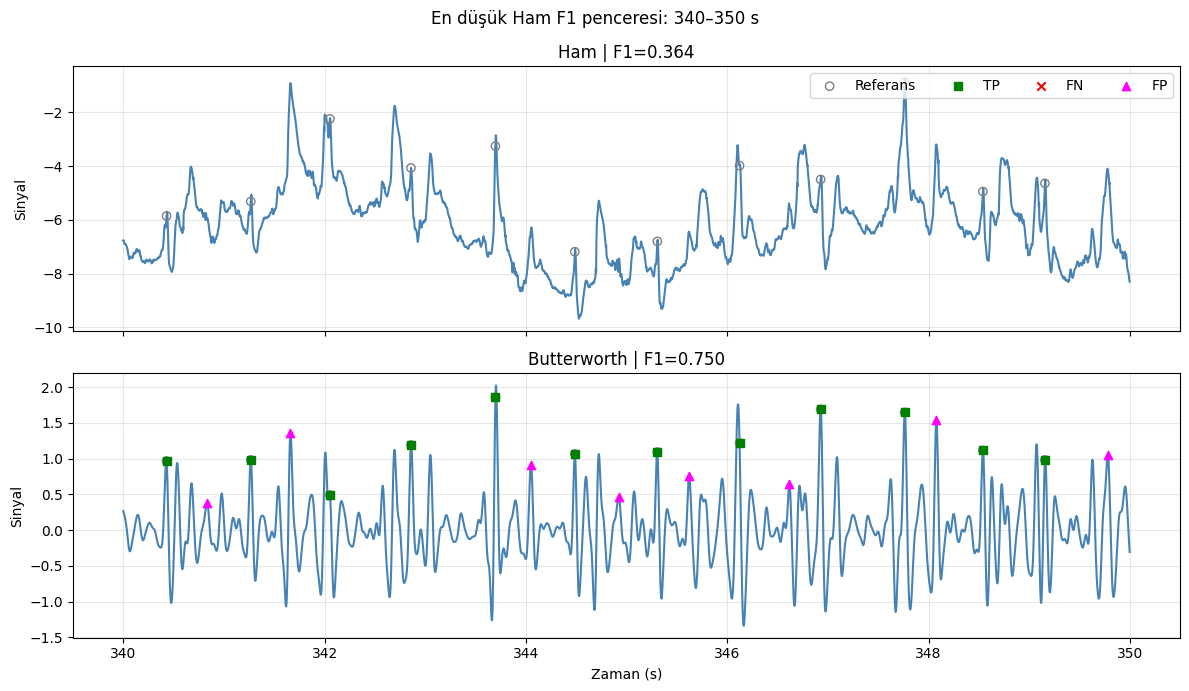

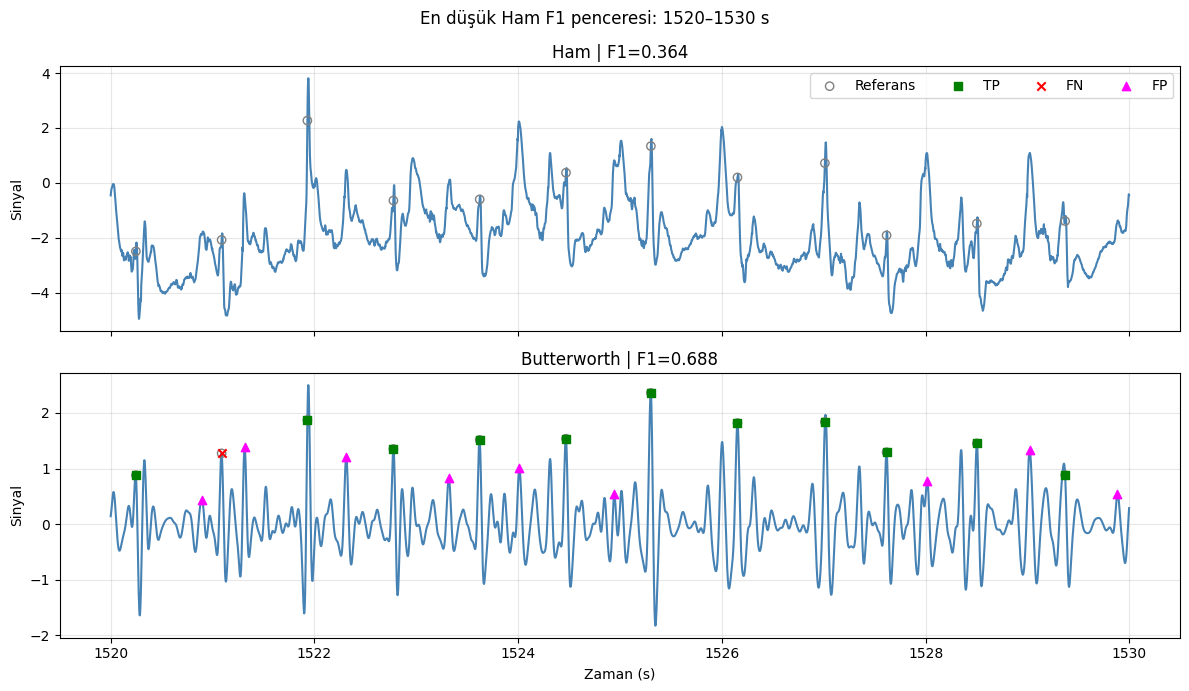

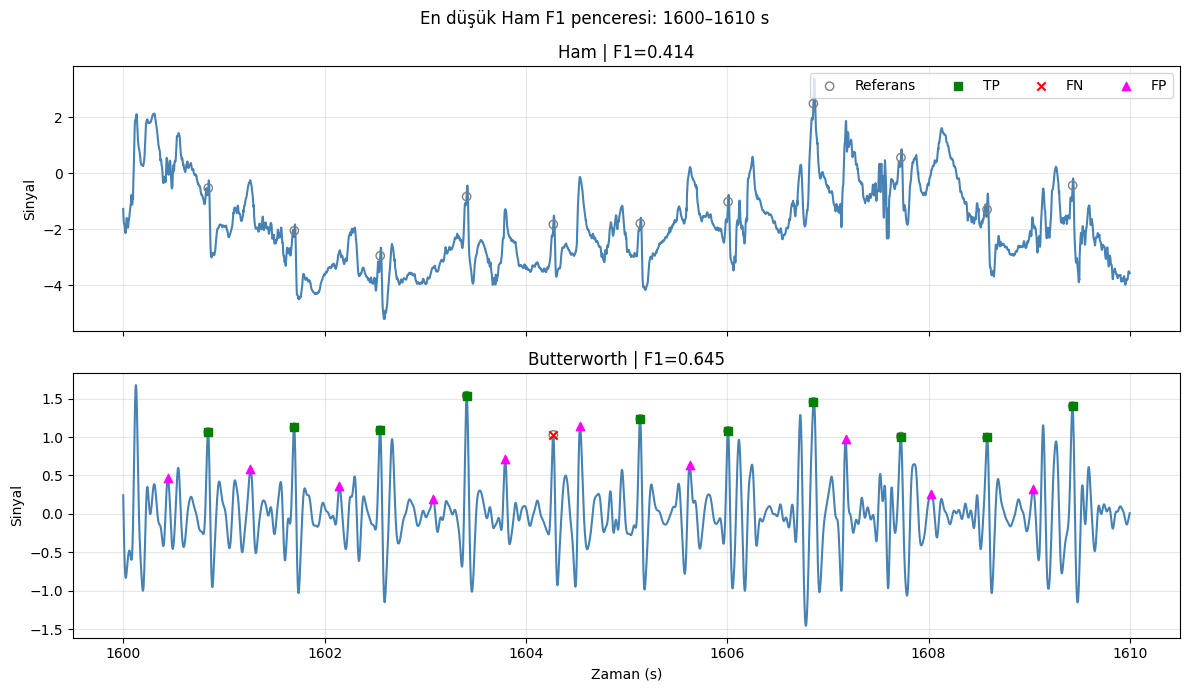

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Önceki hücredeki pencere tablosunu koru.
wide = sonuc_tablosu.copy()

# Aynı pencerelerden, iki yöntem için birlikte 1000 kez örnekle.
rng = np.random.default_rng(0)
n_windows = len(wide)
bootstrap = np.zeros((1000, 3))

for i in range(1000):
    selected = rng.integers(0, n_windows, size=n_windows)

    raw_tp = wide["Ham_TP"].to_numpy()[selected].sum()
    raw_fp = wide["Ham_FP"].to_numpy()[selected].sum()
    raw_fn = wide["Ham_FN"].to_numpy()[selected].sum()

    butter_tp = wide["Butterworth_TP"].to_numpy()[selected].sum()
    butter_fp = wide["Butterworth_FP"].to_numpy()[selected].sum()
    butter_fn = wide["Butterworth_FN"].to_numpy()[selected].sum()

    raw_f1 = 2 * raw_tp / (2 * raw_tp + raw_fp + raw_fn)
    butter_f1 = 2 * butter_tp / (2 * butter_tp + butter_fp + butter_fn)

    bootstrap[i] = [raw_f1, butter_f1, butter_f1 - raw_f1]

# Tüm pencerelerdeki toplam TP, FP ve FN'den gözlenen F1 değerlerini hesapla.
def pooled_f1(tp, fp, fn):
    return 2 * tp.sum() / (2 * tp.sum() + fp.sum() + fn.sum())

observed_raw = pooled_f1(wide["Ham_TP"], wide["Ham_FP"], wide["Ham_FN"])
observed_butter = pooled_f1(
    wide["Butterworth_TP"],
    wide["Butterworth_FP"],
    wide["Butterworth_FN"]
)
observed_difference = observed_butter - observed_raw

ci = np.percentile(bootstrap, [2.5, 97.5], axis=0)

print(f"Pencere sayısı: {n_windows} | Bootstrap tekrar sayısı: 1000")
print(f"Ham F1: {observed_raw:.3f} | %95 GA [{ci[0,0]:.3f}, {ci[1,0]:.3f}]")
print(f"Butterworth F1: {observed_butter:.3f} | %95 GA [{ci[0,1]:.3f}, {ci[1,1]:.3f}]")
print(
    f"F1 farkı (Butterworth - Ham): {observed_difference:.3f} "
    f"| %95 GA [{ci[0,2]:.3f}, {ci[1,2]:.3f}]"
)

# Aynı CSV'de her pencereyi Ham ve Butterworth koşulları için ayrı satırda sakla.
long_tables = []
for condition, prefix in [("Ham", "Ham"), ("Butterworth", "Butterworth")]:
    part = wide[
        ["başlangıç_s", "bitiş_s",
         f"{prefix}_TP", f"{prefix}_FP", f"{prefix}_FN", f"{prefix}_F1"]
    ].copy()
    part.insert(2, "koşul", condition)
    part.columns = ["başlangıç_s", "bitiş_s", "koşul", "TP", "FP", "FN", "F1"]
    long_tables.append(part)

sonuc_tablosu_csv = pd.concat(long_tables, ignore_index=True)
sonuc_tablosu_csv.to_csv("sonuc_tablosu.csv", index=False)
print("Koşul sütunlu CSV kaydedildi: sonuc_tablosu.csv")

# Ham sinyalde F1'i en düşük üç pencereyi bul; her pencereyi iki panelde çiz.
worst_windows = wide.nsmallest(3, "Ham_F1")

for _, row in worst_windows.iterrows():
    start_sample = int(row["başlangıç_s"] * fs)
    end_sample = int(row["bitiş_s"] * fs)
    time_s = np.arange(start_sample, end_sample) / fs

    ref = reference_samples[
        (reference_samples >= start_sample) & (reference_samples < end_sample)
    ]

    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

    for ax, signal, tp_samples, fp_samples, fn_samples, title in [
        (axes[0], raw_signal, raw_tp, raw_fp, raw_fn, "Ham"),
        (axes[1], filtered_signal, filtered_tp, filtered_fp, filtered_fn, "Butterworth"),
    ]:
        ax.plot(time_s, signal[start_sample:end_sample], color="steelblue")
        ax.scatter(ref / fs, signal[ref], marker="o", facecolors="none",
                   edgecolors="gray", label="Referans", zorder=3)

        tp = tp_samples[(tp_samples >= start_sample) & (tp_samples < end_sample)]
        fn = fn_samples[(fn_samples >= start_sample) & (fn_samples < end_sample)]
        fp = fp_samples[(fp_samples >= start_sample) & (fp_samples < end_sample)]

        ax.scatter(tp / fs, signal[tp], marker="s", color="green",
                   label="TP", zorder=4)
        ax.scatter(fn / fs, signal[fn], marker="x", color="red",
                   label="FN", zorder=5)
        ax.scatter(fp / fs, signal[fp], marker="^", color="magenta",
                   label="FP", zorder=5)

        ax.set_ylabel("Sinyal")
        ax.set_title(f"{title} | F1={row[f'{title}_F1']:.3f}")
        ax.grid(True, alpha=0.3)

    axes[1].set_xlabel("Zaman (s)")
    fig.suptitle(
        f"En düşük Ham F1 penceresi: "
        f"{int(row['başlangıç_s'])}–{int(row['bitiş_s'])} s"
    )
    axes[0].legend(ncol=4, loc="upper right")
    plt.tight_layout()
    plt.show()

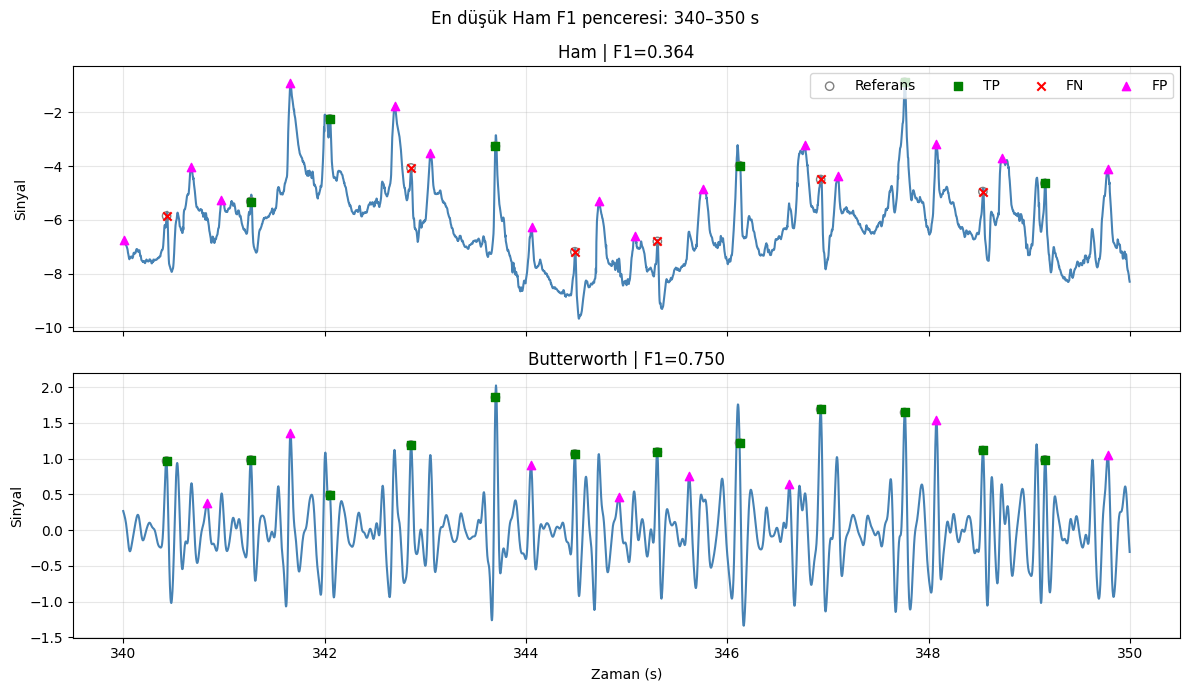

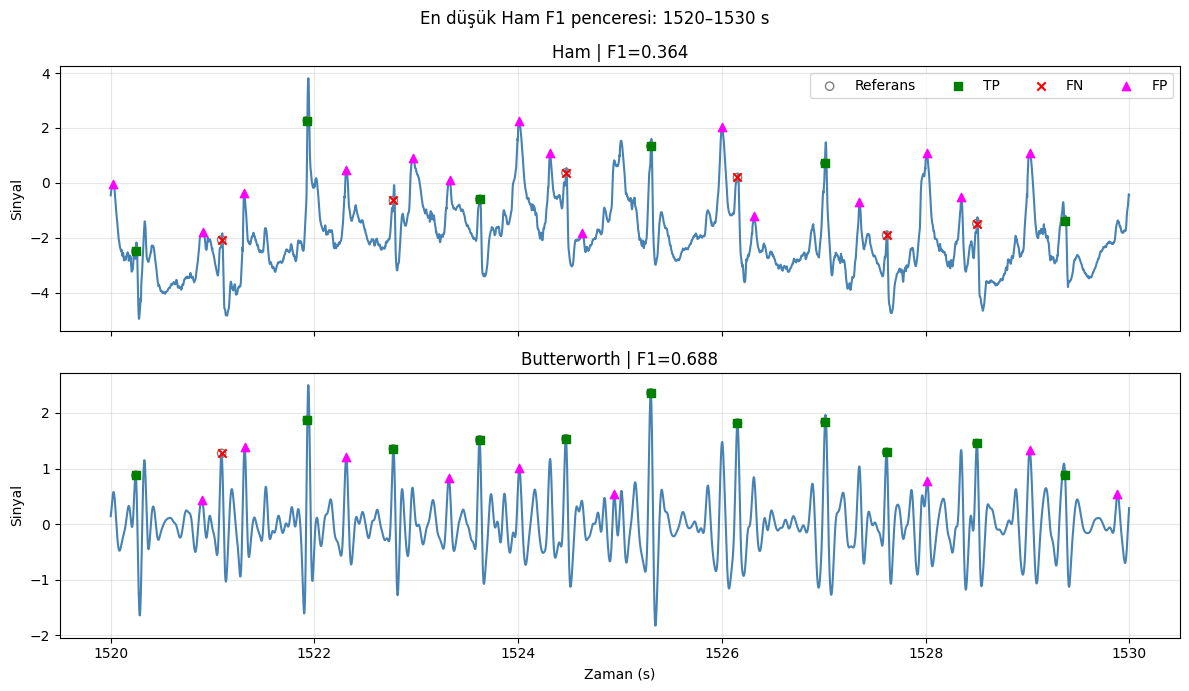

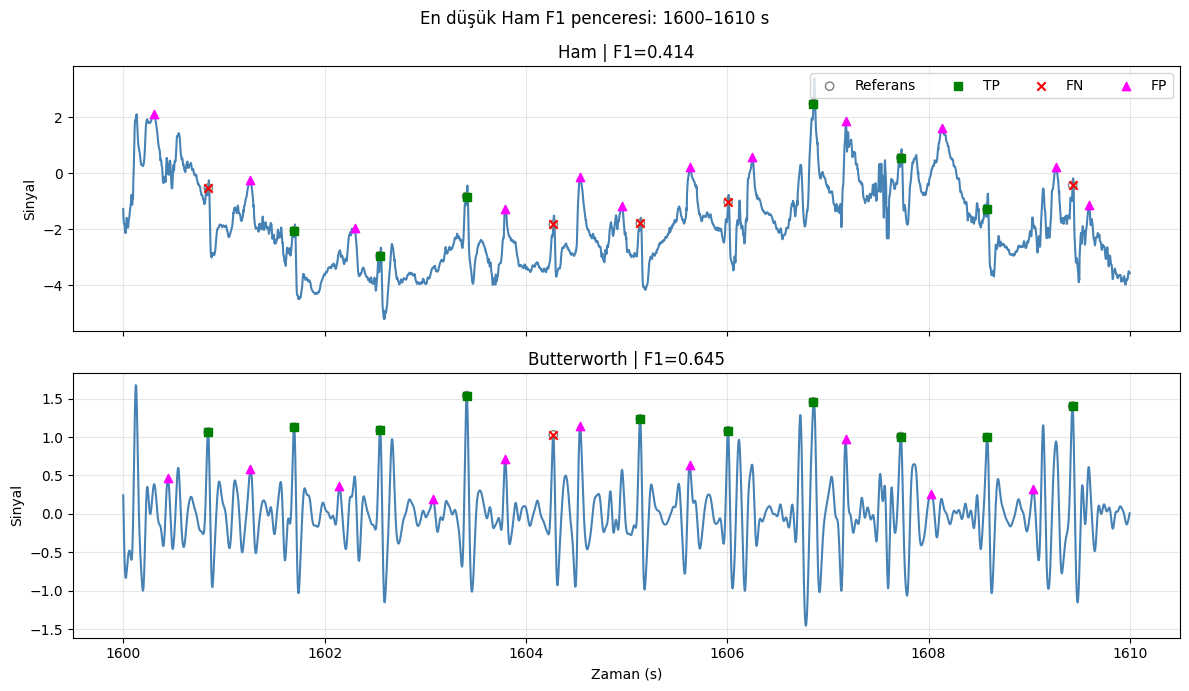

In [ ]:
# Bootstrap hücresinde üzerine yazılmış eşleşme dizilerini yeniden oluştur.
raw_tp_samples, raw_fp_samples, raw_fn_samples = match_events(
    reference_samples, raw_peaks, tolerance_samples
)
filtered_tp_samples, filtered_fp_samples, filtered_fn_samples = match_events(
    reference_samples, filtered_peaks, tolerance_samples
)

# Ham F1'i en düşük üç 10 saniyelik pencereyi yeniden çiz.
for _, row in sonuc_tablosu.nsmallest(3, "Ham_F1").iterrows():
    start_sample = int(row["başlangıç_s"] * fs)
    end_sample = int(row["bitiş_s"] * fs)
    time_s = np.arange(start_sample, end_sample) / fs

    refs = reference_samples[
        (reference_samples >= start_sample) & (reference_samples < end_sample)
    ]

    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

    panels = [
        (axes[0], raw_signal, raw_tp_samples, raw_fp_samples,
         raw_fn_samples, "Ham", row["Ham_F1"]),
        (axes[1], filtered_signal, filtered_tp_samples, filtered_fp_samples,
         filtered_fn_samples, "Butterworth", row["Butterworth_F1"]),
    ]

    for ax, signal, tp_all, fp_all, fn_all, title, f1 in panels:
        ax.plot(time_s, signal[start_sample:end_sample], color="steelblue")

        ax.scatter(refs / fs, signal[refs], marker="o", facecolors="none",
                   edgecolors="gray", label="Referans", zorder=3)

        tp = tp_all[(tp_all >= start_sample) & (tp_all < end_sample)]
        fn = fn_all[(fn_all >= start_sample) & (fn_all < end_sample)]
        fp = fp_all[(fp_all >= start_sample) & (fp_all < end_sample)]

        ax.scatter(tp / fs, signal[tp], marker="s", color="green",
                   label="TP", zorder=4)
        ax.scatter(fn / fs, signal[fn], marker="x", color="red",
                   label="FN", zorder=5)
        ax.scatter(fp / fs, signal[fp], marker="^", color="magenta",
                   label="FP", zorder=5)

        ax.set_ylabel("Sinyal")
        ax.set_title(f"{title} | F1={f1:.3f}")
        ax.grid(True, alpha=0.3)

    axes[1].set_xlabel("Zaman (s)")
    fig.suptitle(
        f"En düşük Ham F1 penceresi: "
        f"{int(row['başlangıç_s'])}–{int(row['bitiş_s'])} s"
    )
    axes[0].legend(ncol=4, loc="upper right")
    plt.tight_layout()
    plt.show()

118e24: 78 gürültülü 10 saniyelik pencere işlendi.
118e06: 78 gürültülü 10 saniyelik pencere işlendi.
118e00: 78 gürültülü 10 saniyelik pencere işlendi.
119e24: 78 gürültülü 10 saniyelik pencere işlendi.
119e06: 78 gürültülü 10 saniyelik pencere işlendi.
119e00: 78 gürültülü 10 saniyelik pencere işlendi.

Pooled F1 ve eşleştirilmiş bootstrap %95 güven aralıkları:
 kayıt      yöntem  pencere_sayısı  F1_pooled  GA95_alt  GA95_üst              karşılaştırma  F1_farkı_pooled
118e24         Ham              78      0.946     0.935     0.956                  yöntem F1              NaN
118e24 Butterworth              78      0.997     0.994     0.999                  yöntem F1              NaN
118e24    Dalgacık              78      0.962     0.953     0.971                  yöntem F1              NaN
118e24 Butterworth              78        NaN     0.041     0.061 Butterworth - Ham F1 farkı            0.051
118e24    Dalgacık              78        NaN     0.011     0.021    Dalgacık - Ham 

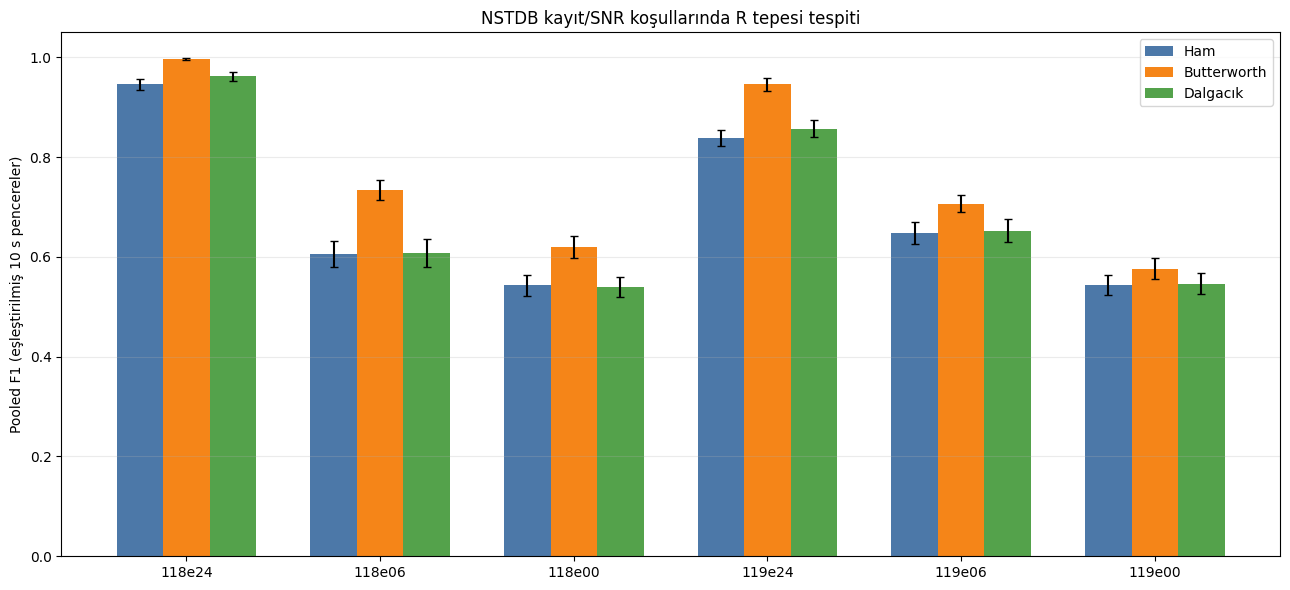

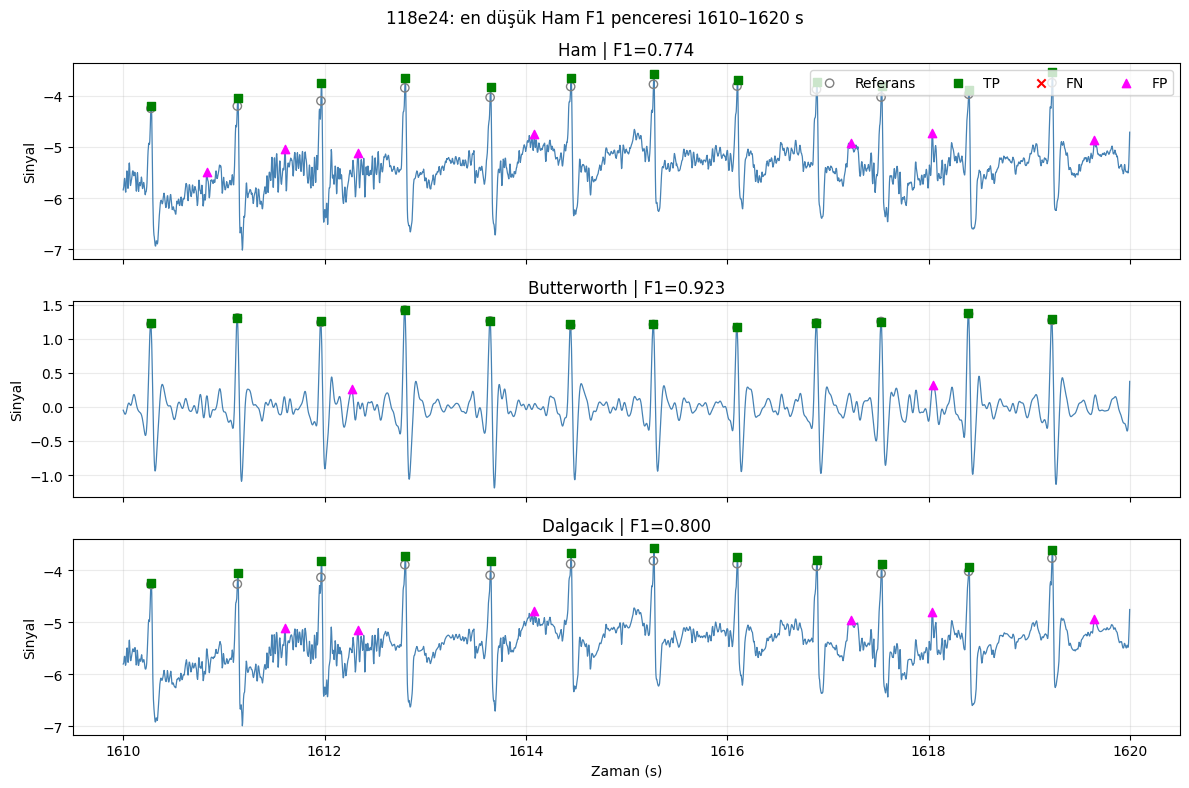

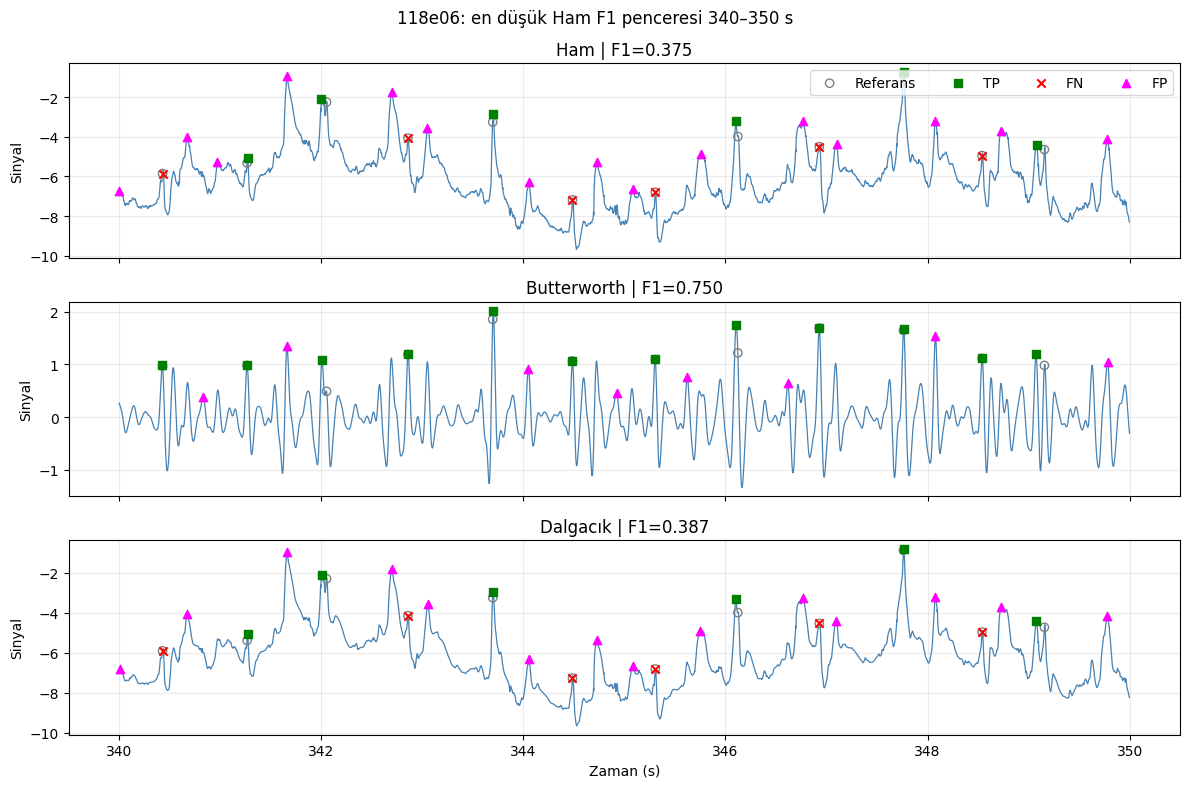

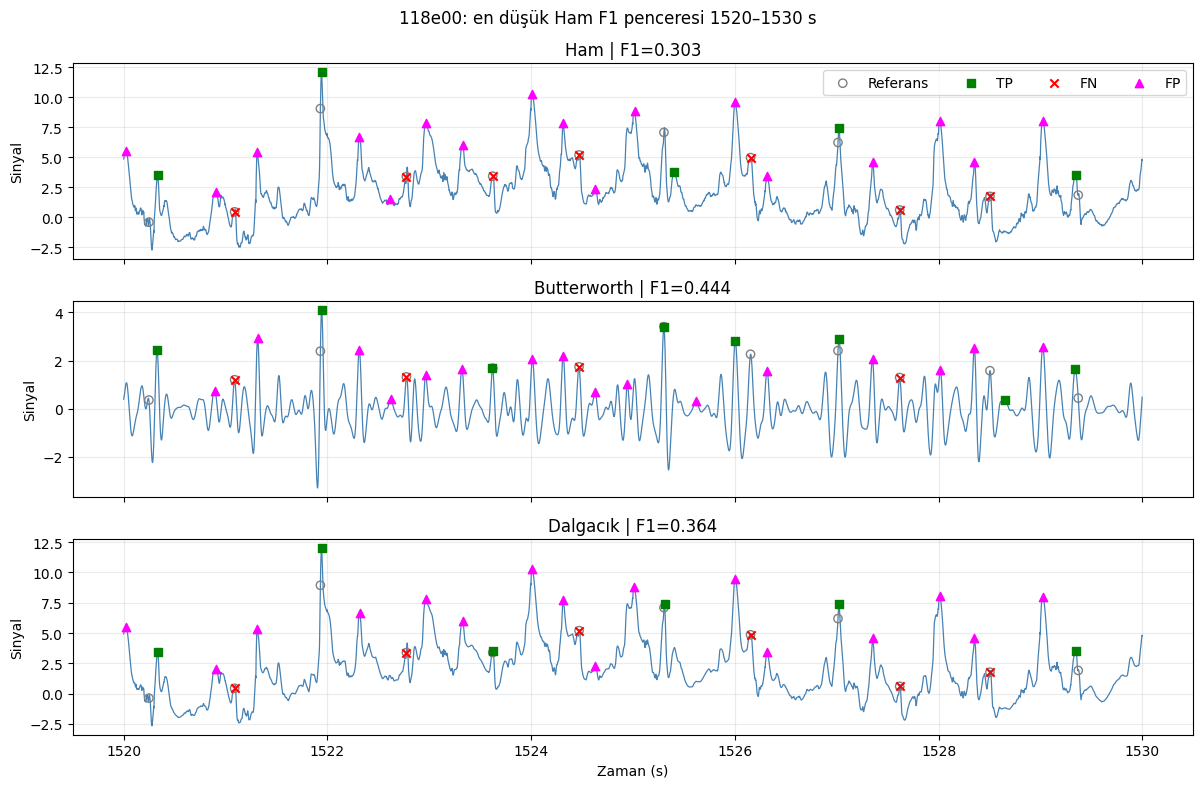

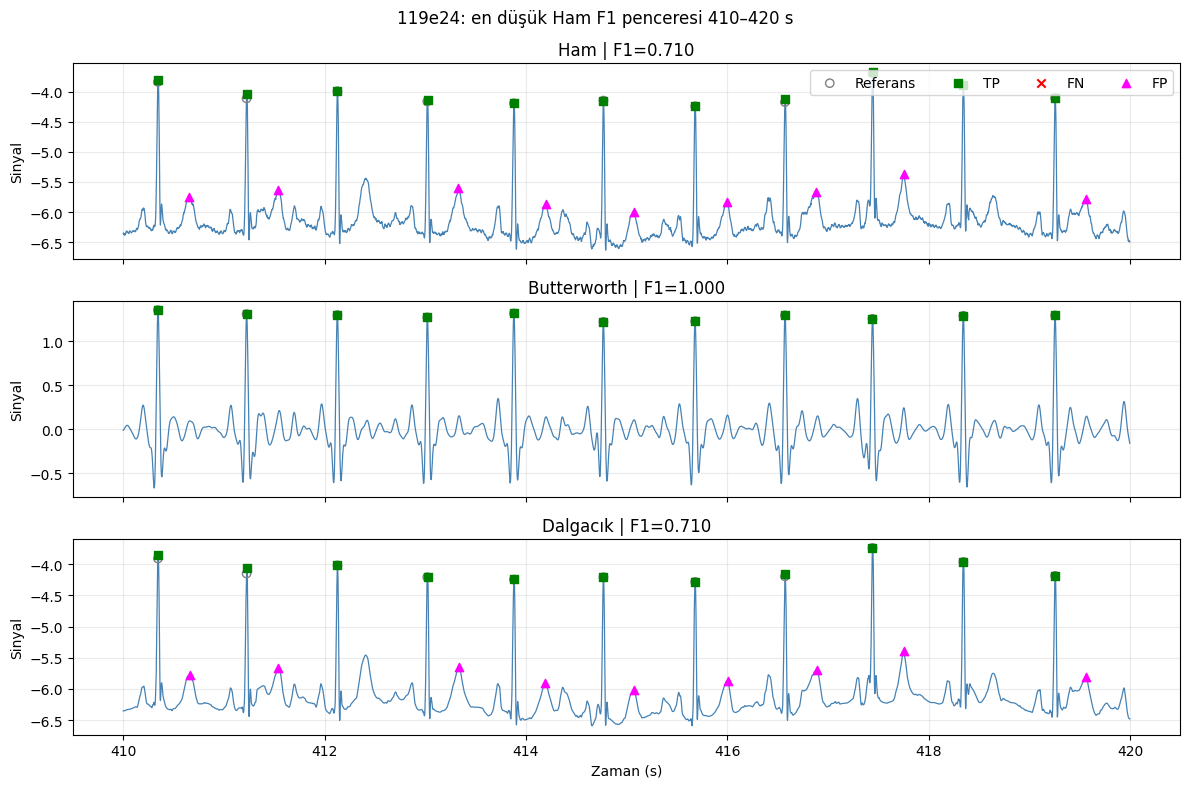

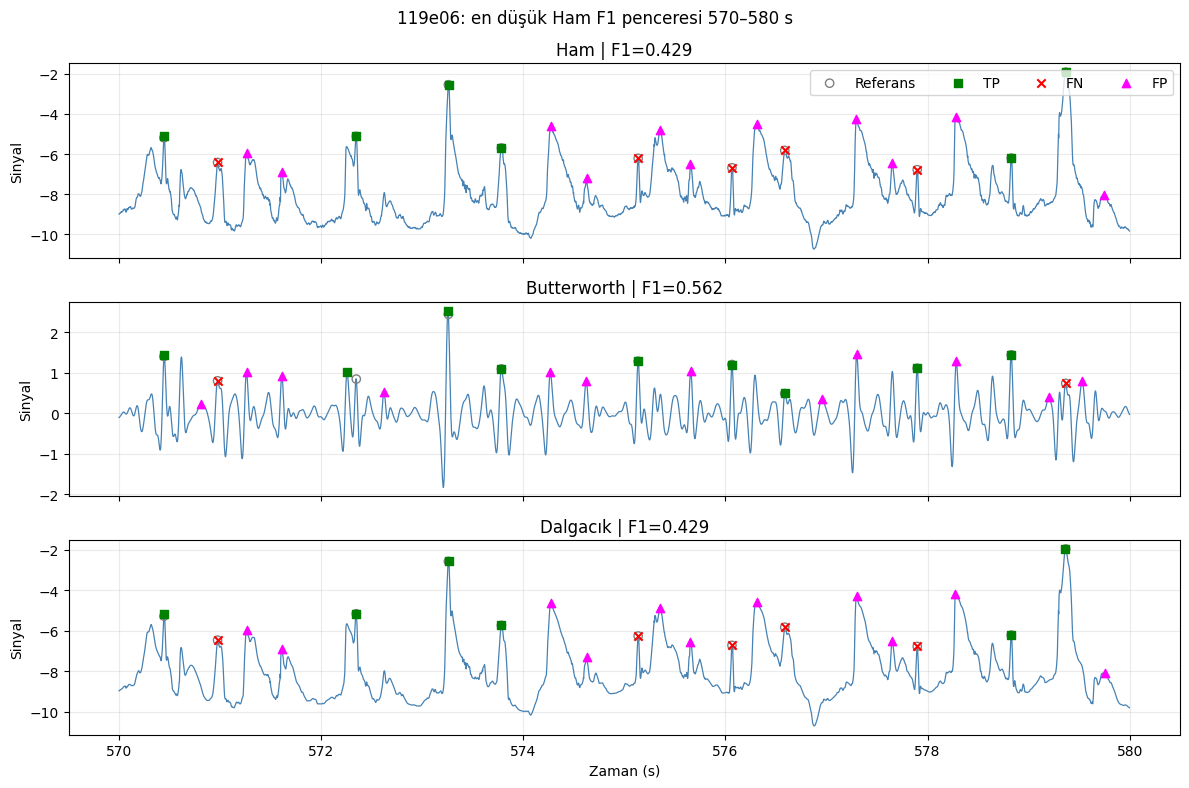

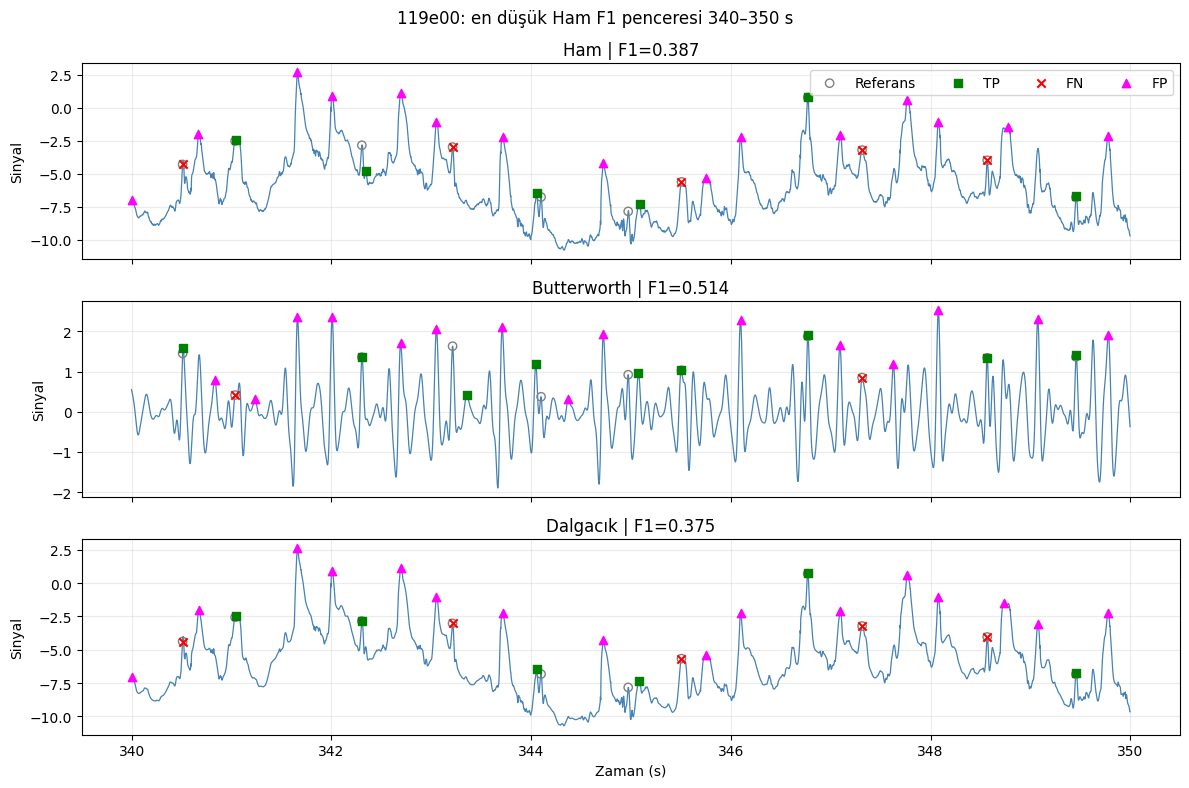

In [6]:
# ÜÇ YÖNTEMİN SON KARŞILAŞTIRMASI
# Ayarlar analiz başlamadan sabitlenmiştir; sonuçlara bakıp eşik/bant değiştirilmez.
# 5–20 Hz Butterworth; find_peaks distance=0.30 s, prominence=0.5;
# eşleştirme toleransı ±150 ms; dalgacık sym4, seviye 8, soft universal threshold.

import wfdb
import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks

RECORDS = ["118e24", "118e06", "118e00", "119e24", "119e06", "119e00"]
BEAT_SYMBOLS = set("NLRBAaJSVrFejnE/fQ?")
BOOTSTRAP_N = 1000
rng = np.random.default_rng(0)


def wavelet_denoise_final(x, name="sym4", requested_level=8):
    w = pywt.Wavelet(name)
    level = min(requested_level, pywt.dwt_max_level(len(x), w.dec_len))
    coeffs = pywt.wavedec(x, w, mode="symmetric", level=level)
    detail = coeffs[-1]
    sigma = np.median(np.abs(detail - np.median(detail))) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(len(x)))
    denoised_coeffs = [coeffs[0]] + [
        pywt.threshold(c, threshold, mode="soft") for c in coeffs[1:]
    ]
    return pywt.waverec(denoised_coeffs, w, mode="symmetric")[:len(x)]


def match_events_final(references, detections, tol):
    detections = np.sort(np.asarray(detections, dtype=int))
    used = np.zeros(len(detections), dtype=bool)
    tp_refs, tp_detections, fn_refs = [], [], []
    for ref in np.asarray(references, dtype=int):
        left = np.searchsorted(detections, ref - tol, side="left")
        right = np.searchsorted(detections, ref + tol, side="right")
        candidates = np.arange(left, right)
        candidates = candidates[~used[candidates]]
        if len(candidates):
            best = candidates[np.argmin(np.abs(detections[candidates] - ref))]
            used[best] = True
            tp_refs.append(ref)
            tp_detections.append(detections[best])
        else:
            fn_refs.append(ref)
    return (np.asarray(tp_refs, dtype=int), np.asarray(tp_detections, dtype=int),
            np.asarray(fn_refs, dtype=int), detections[~used])


rows = []
details = {}
for record_name in RECORDS:
    rec = wfdb.rdrecord(record_name, pn_dir="nstdb")
    ann = wfdb.rdann(record_name, "atr", pn_dir="nstdb")
    signal = np.asarray(rec.p_signal[:, 0], dtype=float)
    fs = float(rec.fs)
    tol = int(round(0.15 * fs))
    distance = int(round(0.30 * fs))

    # Üç yöntemde de tepe bulma parametreleri aynıdır.
    sos = butter(4, [5, 20], btype="bandpass", fs=fs, output="sos")
    filtered = sosfiltfilt(sos, signal)
    wavelet_signal = wavelet_denoise_final(signal)
    detections = {
        "Ham": find_peaks(signal, distance=distance, prominence=0.5)[0],
        "Butterworth": find_peaks(filtered, distance=distance, prominence=0.5)[0],
        "Dalgacık": find_peaks(wavelet_signal, distance=distance, prominence=0.5)[0],
    }
    references = np.asarray([
        int(sample) for sample, symbol in zip(ann.sample, ann.symbol)
        if symbol in BEAT_SYMBOLS
    ], dtype=int)
    matched = {
        method: match_events_final(references, peaks, tol)
        for method, peaks in detections.items()
    }

    # NSTDB düzeni: ilk 5 dk temiz, ardından 2 dk gürültü / 2 dk temiz dönüşümü.
    duration_s = len(signal) / fs
    noisy_intervals = []
    interval_start = 300.0
    while interval_start < duration_s:
        interval_end = min(interval_start + 120.0, duration_s)
        noisy_intervals.append((interval_start, interval_end))
        interval_start += 240.0

    record_rows = []
    for noisy_start, noisy_end in noisy_intervals:
        window_start = noisy_start
        while window_start + 10.0 <= noisy_end:
            window_end = window_start + 10.0
            # Her pencerenin iki ucundaki ±150 ms olayları sınır belirsizliği
            # yaratmasın diye değerlendirme dışı bırakılır.
            left = int(round((window_start + tol / fs) * fs))
            right = int(round((window_end - tol / fs) * fs))
            for method, (tp_refs, tp_dets, fn_refs, fp_dets) in matched.items():
                tp_n = int(np.count_nonzero((tp_refs >= left) & (tp_refs < right)))
                fp_n = int(np.count_nonzero((fp_dets >= left) & (fp_dets < right)))
                fn_n = int(np.count_nonzero((fn_refs >= left) & (fn_refs < right)))
                denom = 2 * tp_n + fp_n + fn_n
                f1 = 2 * tp_n / denom if denom else np.nan
                row = {
                    "kayıt": record_name,
                    "pencere_başlangıç_s": window_start,
                    "pencere_bitiş_s": window_end,
                    "yöntem": method,
                    "TP": tp_n, "FP": fp_n, "FN": fn_n, "F1": f1,
                }
                rows.append(row)
                record_rows.append(row)
            window_start = window_end

    details[record_name] = {
        "fs": fs, "signal": signal, "Butterworth": filtered,
        "Dalgacık": wavelet_signal, "references": references,
        "matched": matched,
    }
    print(f"{record_name}: {len(record_rows) // 3} gürültülü 10 saniyelik pencere işlendi.")

window_results = pd.DataFrame(rows)
window_results.to_csv("nstdb_3_yontem_pencere_sonuclari.csv", index=False)

# Aynı pencere indekslerini üç yönteme birlikte uygulayan eşleştirilmiş bootstrap.
summary_rows = []
for record_name in RECORDS:
    record_data = window_results[window_results["kayıt"] == record_name]
    method_arrays = {}
    for method in ["Ham", "Butterworth", "Dalgacık"]:
        part = record_data[record_data["yöntem"] == method].sort_values("pencere_başlangıç_s")
        method_arrays[method] = part[["TP", "FP", "FN"]].to_numpy(dtype=float)
    n_windows = len(method_arrays["Ham"])
    picked = rng.integers(0, n_windows, size=(BOOTSTRAP_N, n_windows))
    boot_f1 = {}
    for method, values in method_arrays.items():
        totals = values[picked].sum(axis=1)
        denom = 2 * totals[:, 0] + totals[:, 1] + totals[:, 2]
        boot_f1[method] = np.divide(
            2 * totals[:, 0], denom, out=np.zeros(BOOTSTRAP_N), where=denom > 0
        )
        point_totals = values.sum(axis=0)
        point_denom = 2 * point_totals[0] + point_totals[1] + point_totals[2]
        point_f1 = 2 * point_totals[0] / point_denom if point_denom else np.nan
        lo, hi = np.percentile(boot_f1[method], [2.5, 97.5])
        summary_rows.append({
            "kayıt": record_name, "yöntem": method, "pencere_sayısı": n_windows,
            "F1_pooled": point_f1, "GA95_alt": lo, "GA95_üst": hi,
            "karşılaştırma": "yöntem F1",
        })
    for method in ["Butterworth", "Dalgacık"]:
        diff = boot_f1[method] - boot_f1["Ham"]
        summary_rows.append({
            "kayıt": record_name, "yöntem": method, "pencere_sayısı": n_windows,
            "F1_pooled": np.nan, "GA95_alt": np.percentile(diff, 2.5),
            "GA95_üst": np.percentile(diff, 97.5),
            "karşılaştırma": f"{method} - Ham F1 farkı",
            "F1_farkı_pooled": (
                method_arrays[method].sum(axis=0)[0] * 2 /
                (2 * method_arrays[method].sum(axis=0)[0]
                 + method_arrays[method].sum(axis=0)[1]
                 + method_arrays[method].sum(axis=0)[2])
                - method_arrays["Ham"].sum(axis=0)[0] * 2 /
                (2 * method_arrays["Ham"].sum(axis=0)[0]
                 + method_arrays["Ham"].sum(axis=0)[1]
                 + method_arrays["Ham"].sum(axis=0)[2])
            ),
        })

summary = pd.DataFrame(summary_rows)
summary.to_csv("nstdb_3_yontem_bootstrap_ozeti.csv", index=False)
print()
print("Pooled F1 ve eşleştirilmiş bootstrap %95 güven aralıkları:")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print()
print("Kaydedildi: nstdb_3_yontem_pencere_sonuclari.csv")
print("Kaydedildi: nstdb_3_yontem_bootstrap_ozeti.csv")

# Her kayıt/SNR koşulu için üç yöntemin pooled F1 ve %95 GA grafiği.
fig, ax = plt.subplots(figsize=(13, 6))
labels = RECORDS
x = np.arange(len(labels))
width = 0.24
colors = {"Ham": "#4C78A8", "Butterworth": "#F58518", "Dalgacık": "#54A24B"}
for j, method in enumerate(["Ham", "Butterworth", "Dalgacık"]):
    points, lows, highs = [], [], []
    for record_name in RECORDS:
        row = summary[(summary["kayıt"] == record_name) &
                      (summary["yöntem"] == method) &
                      (summary["karşılaştırma"] == "yöntem F1")].iloc[0]
        points.append(row["F1_pooled"])
        lows.append(row["F1_pooled"] - row["GA95_alt"])
        highs.append(row["GA95_üst"] - row["F1_pooled"])
    ax.bar(x + (j - 1) * width, points, width, label=method, color=colors[method],
           yerr=np.array([lows, highs]), capsize=3)
ax.set_xticks(x, labels)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Pooled F1 (eşleştirilmiş 10 s pencereler)")
ax.set_title("NSTDB kayıt/SNR koşullarında R tepesi tespiti")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("nstdb_3_yontem_f1_ga95.png", dpi=180, bbox_inches="tight")
plt.show()

# Her kayıt için en düşük Ham F1 penceresini üç yöntem ve hata işaretleriyle çiz.
for record_name in RECORDS:
    raw_rows = window_results[(window_results["kayıt"] == record_name) &
                              (window_results["yöntem"] == "Ham")]
    worst = raw_rows.loc[raw_rows["F1"].idxmin()]
    fs = details[record_name]["fs"]
    start_s, end_s = worst["pencere_başlangıç_s"], worst["pencere_bitiş_s"]
    start_i, end_i = int(start_s * fs), int(end_s * fs)
    d = details[record_name]
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    for ax, method, values in zip(
        axes, ["Ham", "Butterworth", "Dalgacık"],
        [d["signal"], d["Butterworth"], d["Dalgacık"]]
    ):
        t = np.arange(start_i, end_i) / fs
        ax.plot(t, values[start_i:end_i], color="steelblue", linewidth=0.9)
        refs = d["references"][(d["references"] >= start_i) & (d["references"] < end_i)]
        tp_refs, tp_dets, fn_refs, fp_dets = d["matched"][method]
        tp = tp_dets[(tp_dets >= start_i) & (tp_dets < end_i)]
        fn = fn_refs[(fn_refs >= start_i) & (fn_refs < end_i)]
        fp = fp_dets[(fp_dets >= start_i) & (fp_dets < end_i)]
        ax.scatter(refs / fs, values[refs], marker="o", facecolors="none",
                   edgecolors="gray", label="Referans", zorder=3)
        ax.scatter(tp / fs, values[tp], marker="s", color="green", label="TP", zorder=4)
        ax.scatter(fn / fs, values[fn], marker="x", color="red", label="FN", zorder=5)
        ax.scatter(fp / fs, values[fp], marker="^", color="magenta", label="FP", zorder=5)
        f1_value = window_results[
            (window_results["kayıt"] == record_name) &
            (window_results["pencere_başlangıç_s"] == start_s) &
            (window_results["yöntem"] == method)
        ]["F1"].iloc[0]
        ax.set_ylabel("Sinyal")
        ax.set_title(f"{method} | F1={f1_value:.3f}")
        ax.grid(alpha=0.25)
    axes[0].legend(ncol=4, loc="upper right")
    axes[-1].set_xlabel("Zaman (s)")
    fig.suptitle(f"{record_name}: en düşük Ham F1 penceresi {start_s:.0f}–{end_s:.0f} s")
    fig.tight_layout()
    fig.savefig(f"{record_name}_en_dusuk_ham_f1_3_yontem.png", dpi=160, bbox_inches="tight")
    plt.show()


# NSTDB R tepesi tespiti — sonuç ve rapor taslağı

## Amaç ve yöntem
MIT-BIH Noise Stress Test Database içindeki 118 ve 119 kayıtlarının e24, e06 ve e00 varyantlarında R tepesi tespiti üç yöntemle karşılaştırıldı: ham sinyalde find_peaks temel yöntemi, 5–20 Hz dördüncü derece Butterworth band-pass ve sym4 seviye 8 yumuşak evrensel eşiklemeli dalgacık yöntemi. Tepe bulucu ayarları yöntemler arasında aynı tutuldu (minimum tepe aralığı 0,30 s; prominence 0,5); referans atımla eşleştirme toleransı ±150 ms idi. Ayarlar sonuçlara bakılarak değiştirilmedi. Her kayıtta ilk 5 dakika temiz başlangıç olarak dışarıda bırakıldı; ardından anotasyonla belirlenen gürültülü kısımlardan 10 saniyelik pencereler değerlendirildi (kayıt başına 78 pencere). Sonuçlar pencerelerdeki TP/FP/FN toplamlarından hesaplanan pooled F1 ve pencere bazlı eşleştirilmiş bootstrap ile 1.000 tekrar üzerinden %95 güven aralığıdır.

## Sonuçlar
| Kayıt | Ham F1 (%95 GA) | Butterworth F1 (%95 GA) | Dalgacık F1 (%95 GA) |
|---|---:|---:|---:|
| 118e24 | 0,946 (0,935–0,956) | 0,997 (0,994–0,999) | 0,962 (0,953–0,971) |
| 118e06 | 0,605 (0,579–0,632) | 0,734 (0,713–0,755) | 0,608 (0,581–0,636) |
| 118e00 | 0,543 (0,522–0,563) | 0,620 (0,599–0,641) | 0,540 (0,520–0,559) |
| 119e24 | 0,839 (0,823–0,855) | 0,946 (0,933–0,959) | 0,857 (0,840–0,874) |
| 119e06 | 0,648 (0,626–0,670) | 0,706 (0,690–0,723) | 0,652 (0,629–0,675) |
| 119e00 | 0,543 (0,523–0,564) | 0,576 (0,556–0,597) | 0,546 (0,526–0,568) |

## Kısa yorum
Butterworth altı varyantın tümünde ham yönteme göre daha yüksek pooled F1 verdi; eşleştirilmiş bootstrap farklarının %95 güven aralıkları sıfırın üzerindeydi. Dalgacık, 118e24 ve 119e24 varyantlarında ham yönteme göre küçük artış gösterdi. Diğer dört varyantta dalgacık-ham farkının güven aralığı sıfırı içerdi; bu örneklerde iyileşme gösterilemedi.

## Sınırlılıklar ve yeniden üretilebilirlik
Değerlendirme iki temel EKG kaydının altı NSTDB varyantı ve gürültülü bölümleriyle sınırlıdır; sonuçlar başka hastalara veya klinik kullanıma genellenemez. Bootstrap pencereleri yeniden örnekler; ardışık pencereler arasındaki olası bağımlılığı tamamen modellemez. Son analiz hücresi CSV özetlerini, karşılaştırma grafiğini ve her kayıt için en düşük ham F1 penceresinin üç yöntemli grafiğini üretir. Bunlar proje içi deneysel sonuçlardır, klinik performans iddiası değildir.

In [12]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

required = [
    Path("nstdb_3_yontem_pencere_sonuclari.csv"),
    Path("nstdb_3_yontem_bootstrap_ozeti.csv"),
    Path("nstdb_3_yontem_f1_ga95.png"),
]
figures = sorted(Path(".").glob("*_en_dusuk_ham_f1_3_yontem.png"))
artifacts = required + figures
missing = [str(p) for p in required if not p.exists()]
if missing or len(figures) != 6:
    raise FileNotFoundError(f"Eksik çıktı: {missing}; bulunan kayıt grafiği: {len(figures)}/6")

zip_path = Path("nstdb_analiz_sonuclari.zip")
with ZipFile(zip_path, "w", ZIP_DEFLATED) as archive:
    for path in artifacts:
        archive.write(path, arcname=path.name)
print(f"Paket hazır: {zip_path.name} ({len(artifacts)} dosya)")
print("İçerik:", ", ".join(p.name for p in artifacts))
files.download(str(zip_path))


Paket hazır: nstdb_analiz_sonuclari.zip (9 dosya)
İçerik: nstdb_3_yontem_pencere_sonuclari.csv, nstdb_3_yontem_bootstrap_ozeti.csv, nstdb_3_yontem_f1_ga95.png, 118e00_en_dusuk_ham_f1_3_yontem.png, 118e06_en_dusuk_ham_f1_3_yontem.png, 118e24_en_dusuk_ham_f1_3_yontem.png, 119e00_en_dusuk_ham_f1_3_yontem.png, 119e06_en_dusuk_ham_f1_3_yontem.png, 119e24_en_dusuk_ham_f1_3_yontem.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>